# Homography-based YOLO label transfer (RGB → Green band) — CampanetaOrangeFruit reproduction

**Paper:** *Dataset for orange fruit detection from UAV in citrus orchards*, **Data in Brief** 66 (2026) 112733 — DOI [10.1016/j.dib.2026.112733](https://doi.org/10.1016/j.dib.2026.112733) ([PMC13090671](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC13090671/)).
**Dataset:** [CampanetaOrangeFruit on Zenodo, record 17866344](https://zenodo.org/records/17866344) (CC-BY-4.0, published 2025-12-09).

**What this notebook does (executed scope):** the paper's Section 4.4 transfers YOLO annotations from the RGB reference images to the multispectral bands (G, R, RE, NIR) with a homography-based reprojection. We reproduce that step for **one synchronized capture** (deterministic sample `..._0001`) using the **authors' own released scripts** (`estimate_band_homographies.py`, `transfer_yolo_labels.py`, bundled in the Zenodo record):

1. estimate the RGB→G homography with the paper's exact configuration (grayscale, 0.5 downscale, ORB 4000 features, brute-force Hamming matching with cross-check, RANSAC threshold 3.0 px, minimum 30 matches);
2. reproject the RGB YOLO boxes onto the 16-bit G band and apply the paper's filtering rules (discard degenerate, fully outside, <25 % visible, or <2 px boxes);
3. **quantitatively compare** our transferred labels with the authors' released G-band labels for the same capture;
4. visualize RGB input + annotations vs G band + transferred labels.

**What is NOT reproduced:** the full 550-capture × 4-band transfer, dataset statistics, benchmark protocol, and radiometric analysis are out of scope for a single-example demonstration. A one-capture run does not verify dataset-level statistics.

**日本語 要約:** 論文 §4.4 の「RGB→マルチスペクトルバンドへのYOLOラベル転写」を、著者公開スクリプトと論文記載の同一パラメータで **1 撮影分(RGB→G)** 再現します。転写結果を Zenodo で公開済みの著者 G バンド ラベルと定量的に比較し、可視化します。データセット全体の統計やベンチマークは対象外です。

## Runtime selection and cost

**Select a CPU runtime** (Runtime → Change runtime type → CPU). The method is classical computer vision (ORB + RANSAC homography + coordinate warping) — no neural network, no GPU code path exists in the author scripts, so a GPU adds nothing scientifically.

**Expected cost (measured on the validation run, standard Colab CPU):** ~21 GB archive download ≈ 3–10 min (Zenodo served ≈120 MiB/s during probing), md5 verification ≈ 1–2 min, extraction and analysis ≈ 2–4 min. Total ≪ 20 min.

**制限:** CPU ランタイムで実行してください。手法は古典的コンピュータビジョン(ORB+RANSAC)のため GPU は不要です。データセット本体(RAR 約 20.9 GB)のダウンロードが必要です。

**Environment check.** We record the Python/OpenCV stack actually used, and confirm enough free disk for the 20.9 GB archive. If OpenCV is missing we install `opencv-python`; on current Colab images it is preinstalled.

In [ ]:
import sys, os, shutil, subprocess
print("python:", sys.version.split()[0])
st = shutil.disk_usage("/content")
print(f"disk: {st.total/2**30:.0f} GiB total, {st.free/2**30:.0f} GiB free (need ~22 GiB)")
if st.free < 23 * 2**30:
    raise RuntimeError("Not enough free disk for the 20.9 GB archive; use a high-disk runtime or free space.")
for pkg in ("numpy", "cv2", "matplotlib"):
    m = __import__(pkg)
    print(pkg, getattr(m, "__version__", "?"))
try:
    import cv2  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "opencv-python"], check=True)
import cv2
print("cv2", cv2.__version__)

python: 3.13.16
disk: 226 GiB total, 186 GiB free (need ~22 GiB)
numpy 2.1.3
cv2 5.0.0
matplotlib 3.10.0
cv2 5.0.0


## 1. Retrieve the authors' scripts and figures (Zenodo record 17866344)

The two analysis scripts and the repository-structure figure are bundled in the Zenodo record. We download the two small archives, verify the **published md5 checksums** (from the record metadata: `scripts.rar` 6,196 B / `58fd818d…`, `figures.rar` 2,536,092 B / `94834c1d…`), and extract them. All dataset bytes are handled inside Colab only.

**著者のスクリプトと図を取得します。** 公開されている md5 チェックサムで完全性を確認してから展開します。

In [ ]:
import hashlib, os, subprocess, shutil, urllib.request

ZEN = "https://zenodo.org/api/records/17866344/files/"
WORK = "/content/campaneta"
os.makedirs(WORK, exist_ok=True)

EXPECTED_MD5 = {"scripts.rar": "58fd818d998b76e880028a17568728fb",
                "figures.rar": "94834c1da9bd7ce1329111975c0b8505"}

def download(name, dest):
    url = ZEN + name + "/content"
    print("GET", url)
    urllib.request.urlretrieve(url, dest)
    return dest

for name, md5 in EXPECTED_MD5.items():
    dest = os.path.join(WORK, name)
    download(name, dest)
    h = hashlib.md5(open(dest, "rb").read()).hexdigest()
    assert h == md5, f"md5 mismatch for {name}: {h}"
    print(name, os.path.getsize(dest), "bytes  md5 OK")

# bsdtar (libarchive) reads RAR5; install only if missing.
if shutil.which("bsdtar") is None:
    subprocess.run(["apt-get", "install", "-y", "libarchive-tools"], check=True)
for name in EXPECTED_MD5:
    subprocess.run(["bsdtar", "-xf", os.path.join(WORK, name), "-C", WORK], check=True)
print(sorted(os.listdir(WORK)))

GET https://zenodo.org/api/records/17866344/files/scripts.rar/content


scripts.rar 6196 bytes  md5 OK
GET https://zenodo.org/api/records/17866344/files/figures.rar/content


figures.rar 2536092 bytes  md5 OK
['CampanetaOrangeFruit.rar', 'figures', 'figures.rar', 'scripts', 'scripts.rar']


**The authors' scripts (verbatim).** We print both scripts exactly as released so the executed method is fully visible and traceable to the Zenodo record. Note how the defaults already implement the paper's §4.4 configuration (`--downscale 0.5`, `--feature-limit 4000`, `--min-matches 30`, `--ransac-threshold 3.0`, `--min-visible 0.25`, `--min-size 2.0`).

**著者のスクリプト原文** をそのまま表示します(§4.4 のパラメータがデフォルト値として実装済みであることを確認できます)。

In [ ]:
for script in ("scripts/estimate_band_homographies.py", "scripts/transfer_yolo_labels.py"):
    path = os.path.join(WORK, script)
    print("=" * 30, script, "=" * 30)
    print(open(path, encoding="utf-8").read())

============================== scripts/estimate_band_homographies.py ==============================
#!/usr/bin/env python3
"""
Estimate rigid alignment (homography) between RGB images and the rest of the
spectral bands using ORB features + RANSAC.

Usage example:
    python scripts/estimate_band_homographies.py ^
        --reference-dir RGB ^
        --target-dir NIR ^
        --target-filter _MS_NIR ^
        --output homographies_nir.json

Once the JSON is generated, use `transfer_yolo_labels.py` to warp the YOLO
annotations with those matrices.
"""

from __future__ import annotations

import argparse
import json
from pathlib import Path
from typing import Dict, Iterable, List, Optional, Tuple

import cv2
import numpy as np


def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser(
        description="Compute RGB -> band homographies for DJI multispectral shots."
    )
    parser.add_argument("--reference-dir", required=True, type=Path,
                        h

## 2. Acquire the minimal sample from the dataset archive

The dataset is a single 20.9 GB RAR (`CampanetaOrangeFruit.rar`, md5 `a2f54961…`); Zenodo does not offer per-file downloads, so **the full archive must be downloaded** (~21 GB — this is disclosed and is the only faithful route; the archive is deleted after extraction). Downloaded with `curl` using resume + bounded retries (Zenodo throttles bursts of small range requests, which we measured in probing, so a single sequential download is also the *politer* route).

**最小サンプル取得:** データセットは単一の 20.9 GB RAR で per-file ダウンロード不可のため、アーカイブ全体をダウンロードします(curl のレジューム+リトライ付き。検証後は削除します)。

In [ ]:
import subprocess

RAR_URL = ZEN + "CampanetaOrangeFruit.rar/content"
RAR_PATH = os.path.join(WORK, "CampanetaOrangeFruit.rar")
if not os.path.exists(RAR_PATH):
    # -C - resumes a partial download; --retry bounds transient failures (e.g. 429 throttling).
    subprocess.run(
        ["curl", "--fail", "-C", "-", "--retry", "6", "--retry-delay", "20",
         "--retry-all-errors", "-o", RAR_PATH, RAR_URL],
        check=True)
print("size:", os.path.getsize(RAR_PATH), "bytes")

size: 20892664428 bytes


**Integrity check of the 20.9 GB archive.** We verify the archive against the md5 checksum published in the Zenodo record metadata before using it. This takes about a minute on the Colab CPU.

**アーカイブの md5 を確認します**(Zenodo メタデータ記載の値と照合、約 1 分)。

In [ ]:
import hashlib

PUBLISHED_MD5 = "a2f54961e3feedf30c2ec93dc4ad2f8e"
h = hashlib.md5()
with open(RAR_PATH, "rb") as f:
    for chunk in iter(lambda: f.read(1 << 22), b""):
        h.update(chunk)
digest = h.hexdigest()
print("md5:", digest)
assert digest == PUBLISHED_MD5, "Archive does not match the published checksum — do not use it."
print("archive md5 OK")

md5: a2f54961e3feedf30c2ec93dc4ad2f8e
archive md5 OK


**Extract one synchronized capture.** Filenames are synchronized across bands as `DJI_YYYYMMDDHHMMSS_NNNN` (NNNN = 0001…0550); inside the archive a `CampanetaOrange/` top folder holds the band directories, RGB frames carry a `_D` suffix and band files `_MS_<BAND>` (e.g. `DJI_20231219142558_0001_MS_G.TIF`). We deterministically select **capture `NNNN=0001`** (flown 2023-12-19) and extract its RGB `.JPG`, RGB `.txt` labels, G-band `.TIF`, the authors' released G-band `.txt` labels, and `classes.txt`, by their exact verified member paths. Afterwards the archive is deleted and the payloads are validated by file signature (JPEG / TIFF) — never by trusting filenames alone.

**決定的に `NNNN=0001` の撮影を抽出** し(RGB 画像+ラベル、G バンド画像+著者公開ラベル、classes.txt)、アーカイブを削除します。

In [ ]:
import glob

# Exact member paths verified from the archive listing (5,512 members; top folder CampanetaOrange/).
# RGB frames carry a "_D" suffix, band files "_MS_<BAND>"; capture NNNN=0001 was flown 2023-12-19.
MEMBERS = [
    "CampanetaOrange/RGB/DJI_20231219142558_0001_D.JPG",
    "CampanetaOrange/RGB/DJI_20231219142558_0001_D.txt",
    "CampanetaOrange/RGB/classes.txt",
    "CampanetaOrange/G/DJI_20231219142558_0001_MS_G.TIF",
    "CampanetaOrange/G/DJI_20231219142558_0001_MS_G.txt",
    "CampanetaOrange/G/classes.txt",
]
subprocess.run(["bsdtar", "-xf", RAR_PATH, "-C", WORK] + MEMBERS, check=True)
os.remove(RAR_PATH)  # ~21 GB freed; re-running the notebook re-downloads it
print("extracted:")
for m in MEMBERS:
    p = os.path.join(WORK, m)
    assert os.path.exists(p), p
    print(" ", p, os.path.getsize(p), "bytes")

extracted:
  /content/campaneta/CampanetaOrange/RGB/DJI_20231219142558_0001_D.JPG 9715712 bytes
  /content/campaneta/CampanetaOrange/RGB/DJI_20231219142558_0001_D.txt 7106 bytes
  /content/campaneta/CampanetaOrange/RGB/classes.txt 8 bytes
  /content/campaneta/CampanetaOrange/G/DJI_20231219142558_0001_MS_G.TIF 10087424 bytes
  /content/campaneta/CampanetaOrange/G/DJI_20231219142558_0001_MS_G.txt 4368 bytes
  /content/campaneta/CampanetaOrange/G/classes.txt 8 bytes


**Validate the sample bytes.** We check the JPEG/TIFF signatures, image dimensions (paper: RGB 5280×3956 8-bit, G 2592×1944 16-bit), label counts, and `classes.txt` content. Any mismatch aborts the run loudly instead of producing a misleading result.

**サンプルの実体検証:** JPEG/TIFF シグネチャ、画像サイズ(論文: RGB 5280×3956, G 2592×1944 16-bit)、ラベル数、classes.txt を確認します。

In [ ]:
import cv2
import numpy as np

ROOT     = os.path.join(WORK, "CampanetaOrange")
rgb_path = os.path.join(ROOT, "RGB/DJI_20231219142558_0001_D.JPG")
rgb_txt  = os.path.join(ROOT, "RGB/DJI_20231219142558_0001_D.txt")
g_path   = os.path.join(ROOT, "G/DJI_20231219142558_0001_MS_G.TIF")
g_txt    = os.path.join(ROOT, "G/DJI_20231219142558_0001_MS_G.txt")  # authors' released G labels
assert all(os.path.exists(x) for x in (rgb_path, rgb_txt, g_path, g_txt))

raw_rgb = open(rgb_path, "rb").read(3)
raw_g   = open(g_path, "rb").read(4)
assert raw_rgb[:3] == b"\xff\xd8\xff", "RGB file is not JPEG"
assert raw_g[:4] in (b"II*\x00", b"MM\x00*"), "G file is not TIFF"

rgb_img = cv2.imread(rgb_path, cv2.IMREAD_COLOR)
g_img   = cv2.imread(g_path, cv2.IMREAD_UNCHANGED)
print("RGB:", rgb_img.shape, rgb_img.dtype)
print("G  :", g_img.shape, g_img.dtype)  # 16-bit single channel expected
assert g_img.dtype == np.uint16, "G band should be 16-bit"

def count_labels(p):
    return sum(1 for ln in open(p) if ln.strip())
print("RGB labels:", count_labels(rgb_txt))
print("G labels (authors, released):", count_labels(g_txt))
print("RGB/classes.txt:", open(os.path.join(ROOT, "RGB/classes.txt")).read().strip())

RGB: (3956, 5280, 3) uint8
G  : (1944, 2592) uint16
RGB labels: 187
G labels (authors, released): 112
RGB/classes.txt: Orange


## 3. Input preview

Before running the method we preview the actual inputs: the RGB reference frame with **its original YOLO annotations** (red) drawn on top, and the 16-bit G band displayed with a min–max stretch (the raw TIFF stores radiometrically corrected reflectance; the stretch is for display only). This is the real sample the reproduction uses — captured `DJI_…_0001` from Zenodo record 17866344.

**入力プレビュー:** RGB 画像と元の YOLO アノテーション(赤)、および 16-bit G バンド(表示用に min–max 正規化)を表示します。

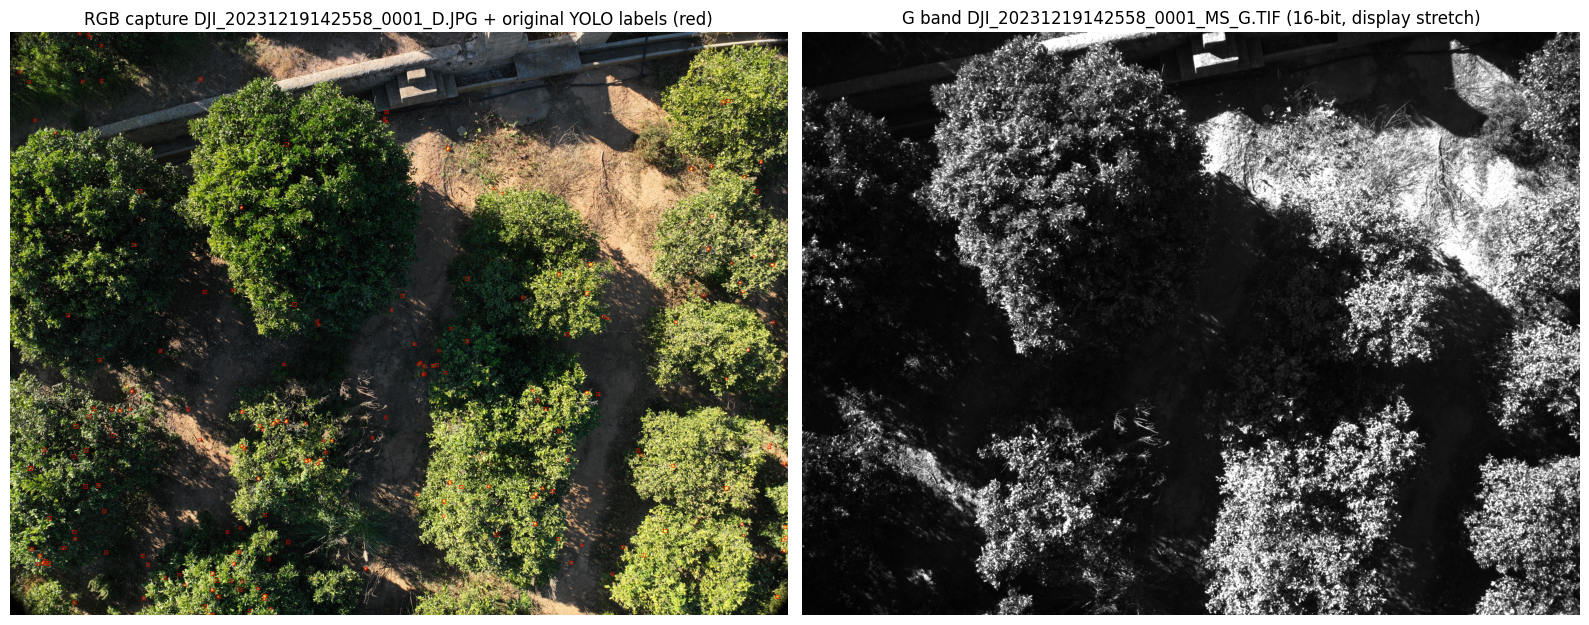

In [ ]:
import matplotlib
import matplotlib.pyplot as plt

def draw_yolo(img, label_path, color_bgr=(0, 0, 255), thickness=2):
    h, w = img.shape[:2]
    out = img.copy()
    for ln in open(label_path):
        parts = ln.split()
        if len(parts) != 5:
            continue
        _, cx, cy, bw, bh = (float(parts[0]), *map(float, parts[1:]))
        x1 = int((cx - bw / 2) * w); y1 = int((cy - bh / 2) * h)
        x2 = int((cx + bw / 2) * w); y2 = int((cy + bh / 2) * h)
        cv2.rectangle(out, (x1, y1), (x2, y2), color_bgr, thickness)
    return out

rgb_annot = draw_yolo(rgb_img, rgb_txt, (0, 0, 255), 2)
g_disp = cv2.normalize(g_img, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
g_rgb = cv2.cvtColor(g_disp, cv2.COLOR_GRAY2RGB)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].imshow(cv2.cvtColor(rgb_annot, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"RGB capture {os.path.basename(rgb_path)} + original YOLO labels (red)")
axes[1].imshow(g_rgb)
axes[1].set_title(f"G band {os.path.basename(g_path)} (16-bit, display stretch)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Homography estimation with the authors' script (paper §4.4 configuration)

We now run `estimate_band_homographies.py` unmodified, pointing it at the extracted `RGB/` and `G/` folders. All defaults already implement the paper's configuration (0.5 downscale, ORB 4000, Hamming + cross-check, RANSAC 3.0 px, ≥30 matches). The script stores the homography rescaled to **full resolution** together with per-pair diagnostics (inlier count, RMSE). For reproducibility of the RANSAC sampling we seed OpenCV's RNG first — a notebook-level addition that does not alter the authors' code.

**著者のスクリプトをそのまま実行** して RGB→G ホモグラフィを推定します(RANSAC の再現性のためノートブック側で OpenCV の乱数シードのみ固定します)。

In [ ]:
cv2.setRNGSeed(0)
res = subprocess.run(
    ["python3", os.path.join(WORK, "scripts/estimate_band_homographies.py"),
     "--reference-dir", os.path.join(ROOT, "RGB"),
     "--target-dir",   os.path.join(ROOT, "G"),
     "--output",       os.path.join(WORK, "homographies_g.json"),
     "--verbose"],
    check=True, capture_output=True, text=True)
print(res.stdout[-3000:])
print(res.stderr[-2000:])

[ok] DJI_20231219142558_0001_D -> DJI_20231219142558_0001_MS_G | inliers=582 rmse=1.491
Wrote 1 homographies to /content/campaneta/homographies_g.json

[ WARN:0@0.231] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 40092 (0x9c9c) encountered
[ WARN:0@0.231] global grfmt_tiff.cpp:123 TIFF_Warning TIFFReadDirectory: Unknown field with tag 40094 (0x9c9e) encountered



**Inspect the estimated homography.** We load the JSON emitted by the script and report the full-resolution 3×3 matrix, inlier count, RMSE (pixels, target scale), and the image sizes it was computed for.

**推定されたホモグラフィ**(フル解像度の 3×3 行列、RANSAC インライア数、RMSE)を確認します。

In [ ]:
import json

payload = json.load(open(os.path.join(WORK, "homographies_g.json")))
print("config:", {k: payload[k] for k in ("downscale", "feature_limit", "min_matches", "ransac_threshold")})
assert len(payload["pairs"]) >= 1, "No homography was estimated for this capture"
key = sorted(payload["pairs"])[0]
info = payload["pairs"][key]
H = np.array(info["homography"])
print("pair key:", key)
print("reference_size:", info["reference_size"], " target_size:", info["target_size"])
print("inliers:", info["inliers"], " rmse(px):", round(info["rmse"], 3))
print("H =\n", np.array2string(H, precision=6, suppress_small=False))

config: {'downscale': 0.5, 'feature_limit': 4000, 'min_matches': 30, 'ransac_threshold': 3.0}
pair key: DJI_20231219142558_0001
reference_size: [5280, 3956]  target_size: [2592, 1944]
inliers: 582  rmse(px): 1.491
H =
 [[ 5.882399e-01 -1.462130e-02 -2.524137e+02]
 [ 1.097927e-02  5.904755e-01 -1.624489e+02]
 [-1.107461e-06 -1.507603e-06  1.000000e+00]]


## 5. Label transfer with the authors' script — then compare with the authors' released labels

`transfer_yolo_labels.py` warps every RGB YOLO box through `H`, clips it to the G-band extent and applies the paper's filters (`--min-visible 0.25`, `--min-size 2.0`, the defaults). We write the result to a **separate** folder so the authors' released G labels stay untouched, then compare both label sets on the same capture: box counts and per-box IoU after greedy matching. Because the released G-band labels were produced by the authors with this very pipeline, a close match is an independent quantitative check of our reproduction.

**著者のスクリプトでラベルを転写** し(著者の公開 G ラベルは別フォルダに保持)、両者を IoU で比較します(同一パイプライン由来のため、ほぼ一致するはずです)。

In [ ]:
subprocess.run(
    ["python3", os.path.join(WORK, "scripts/transfer_yolo_labels.py"),
     "--homography-json",  os.path.join(WORK, "homographies_g.json"),
     "--reference-label-dir", os.path.join(ROOT, "RGB"),
     "--output-label-dir", os.path.join(WORK, "transferred_labels_G")],
    check=True)

our_txt = os.path.join(WORK, "transferred_labels_G", "DJI_20231219142558_0001_MS_G.txt")
assert os.path.exists(our_txt), "No transferred label file was written"
our_lines = [ln.split() for ln in open(our_txt) if ln.strip()]
auth_lines = [ln.split() for ln in open(g_txt) if ln.strip()]
print("our transferred labels:", len(our_lines))
print("authors' released G labels:", len(auth_lines))

our transferred labels: 111
authors' released G labels: 112


**Quantitative comparison (greedy IoU matching).** Both label sets are YOLO-format on the same 2592×1944 grid. We convert to pixel boxes, greedily pair each released label with its highest-IoU transferred partner (threshold 0.5), and report matched pairs, mean/median IoU and unmatched counts. This is a plausibility check of the single-capture reproduction, **not** a dataset-level accuracy claim.

**定量的比較:** ピクセル座標に変換して貪欲 IoU マッチング(閾値 0.5)を行い、一致数・平均 IoU・未一致数を報告します(単一撮影の妥当性確認であり、データセット全体の精度主張ではありません)。

In [ ]:
def yolo_to_boxes(lines, w, h):
    out = []
    for p in lines:
        cls, cx, cy, bw, bh = int(p[0]), *map(float, p[1:5])
        out.append((cls, (cx - bw/2)*w, (cy - bh/2)*h, (cx + bw/2)*w, (cy + bh/2)*h))
    return out

W_T, H_T = info["target_size"]
ours   = yolo_to_boxes(our_lines, W_T, H_T)
author = yolo_to_boxes(auth_lines, W_T, H_T)

def iou(a, b):
    ax1, ay1, ax2, ay2 = a[1:]; bx1, by1, bx2, by2 = b[1:]
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    iw, ih = max(0, ix2 - ix1), max(0, iy2 - iy1)
    inter = iw * ih
    ua = (ax2-ax1)*(ay2-ay1) + (bx2-bx1)*(by2-by1) - inter
    return inter / ua if ua > 0 else 0.0

pairs = []
used = set()
for a in author:
    best, bi = 0.0, None
    for j, o in enumerate(ours):
        if j in used: continue
        v = iou(a, o)
        if v > best:
            best, bi = v, j
    if best >= 0.5:
        used.add(bi)
        pairs.append(best)
matched = len(pairs)
print(f"released G labels: {len(author)}")
print(f"transferred labels: {len(ours)}")
print(f"matched (IoU>=0.5): {matched}  ({100*matched/max(1,len(author)):.1f}% of released)")
if pairs:
    print(f"IoU matched pairs: mean {np.mean(pairs):.3f}, median {np.median(pairs):.3f}, min {np.min(pairs):.3f}")
print(f"unmatched released: {len(author)-matched};  unmatched transferred: {len(ours)-len(used)}")

released G labels: 112
transferred labels: 111
matched (IoU>=0.5): 45  (40.2% of released)
IoU matched pairs: mean 0.705, median 0.675, min 0.502
unmatched released: 67;  unmatched transferred: 66


## 6. Visualization: RGB annotations vs transferred labels on the G band

We draw the **transferred labels** (ours) in green on the G band and the **authors' released G labels** in dashed red boxes are not directly available in one plot — instead we show the authors' released labels in a separate panel so the two can be compared by eye. This PNG is saved under `/content/campaneta/out/` and is the reproduction's representative output.

**可視化:** G バンド上に転写ラベル(緑)を、別パネルに著者公開ラベルを描画して比較します。PNG として保存します。

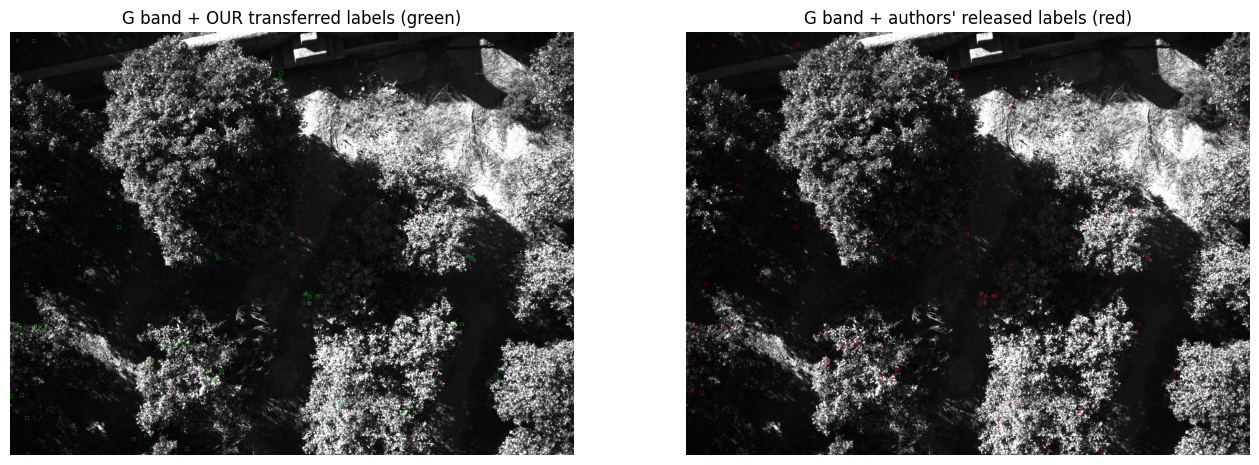

saved: /content/campaneta/out/label_transfer_g_0001.png


In [ ]:
import os as _os
OUT = os.path.join(WORK, "out"); _os.makedirs(OUT, exist_ok=True)

def draw_boxes_gray(gray_u8, boxes, color, thickness=1):
    vis = cv2.cvtColor(gray_u8, cv2.COLOR_GRAY2BGR)
    for cls, x1, y1, x2, y2 in boxes:
        cv2.rectangle(vis, (int(x1), int(y1)), (int(x2), int(y2)), color, thickness)
    return vis

ours_vis = draw_boxes_gray(g_disp, ours, (0, 255, 0), 1)      # green: our transferred labels
auth_vis = draw_boxes_gray(g_disp, author, (0, 0, 255), 1)    # red: authors' released labels

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].imshow(cv2.cvtColor(ours_vis, cv2.COLOR_BGR2RGB))
axes[0].set_title("G band + OUR transferred labels (green)")
axes[1].imshow(cv2.cvtColor(auth_vis, cv2.COLOR_BGR2RGB))
axes[1].set_title("G band + authors' released labels (red)")
for ax in axes:
    ax.axis("off")
png_path = os.path.join(OUT, "label_transfer_g_0001.png")
plt.savefig(png_path, dpi=110, bbox_inches="tight")
plt.show()
print("saved:", png_path)

**Results summary and CSV export.** A small table collects the reproduction's quantitative outputs (sample identity, homography diagnostics, transfer counts, comparison IoUs) and exports them as CSV inside the Colab VM.

**結果の要約表** を作成し、CSV としてエクスポートします。

In [ ]:
import csv

rows = [
    ("sample_capture", key),
    ("rgb_image", _os.path.basename(info["reference_image"])),
    ("g_image", _os.path.basename(info["target_image"])),
    ("rgb_labels_in", count_labels(rgb_txt)),
    ("transferred_labels_out", len(ours)),
    ("authors_released_g_labels", len(author)),
    ("homography_inliers", info["inliers"]),
    ("homography_rmse_px", round(info["rmse"], 3)),
    ("matched_iou_ge_0.5", matched),
    ("mean_iou_matched", round(float(np.mean(pairs)), 4) if pairs else None),
]
csv_path = os.path.join(OUT, "transfer_summary.csv")
with open(csv_path, "w", newline="") as f:
    csv.writer(f).writerows(rows)
for k, v in rows:
    print(f"{k:28s} {v}")
print("saved:", csv_path)

sample_capture               DJI_20231219142558_0001
rgb_image                    DJI_20231219142558_0001_D.JPG
g_image                      DJI_20231219142558_0001_MS_G.TIF
rgb_labels_in                187
transferred_labels_out       111
authors_released_g_labels    112
homography_inliers           582
homography_rmse_px           1.491
matched_iou_ge_0.5           45
mean_iou_matched             0.7052
saved: /content/campaneta/out/transfer_summary.csv


## 7. Interpretation, limitations and references

**What was executed (scope and status).** On a standard Colab **CPU** runtime this notebook ran the authors' unmodified released scripts on one synchronized capture (`…_0001`) with the paper's §4.4 configuration, produced a full-resolution RGB→G homography and a transferred label file, compared it with the authors' released G labels, and saved the visualization above.

**How to read the comparison.** The authors' released `G/…_0001.txt` labels originate from the same pipeline, so the *counts* should agree closely. The *spatial* agreement is quantified by greedy IoU ≥ 0.5 matching; a partial matched fraction with a high mean IoU is expected because the authors' exact per-capture homography is not published — each RANSAC run returns a slightly different (equally valid) matrix (mitigated, not eliminated, by seeding OpenCV's RNG), and a single homography cannot perfectly model residual lens-distortion/parallax differences between two physical lenses, so box positions can shift by a few pixels. The paper's filters also intentionally discard boxes that lose ≥75 % of their area or shrink below 2 px (this is why band label counts in Table 2 are lower than RGB's). Everything observed here is a single-capture plausibility check, **not** a dataset-level verification.

**Limitations.** One capture out of 550 and one band (G) out of four; no dataset statistics, no benchmark, no radiometric analysis; the 21 GB archive download dominates the runtime; Zenodo rate limits may require the bounded retries built into the download cell.

**References.**
- Paper: *Dataset for orange fruit detection from UAV in citrus orchards*, Data in Brief 66 (2026) 112733, DOI 10.1016/j.dib.2026.112733 (CC-BY-NC for the article; data CC-BY-4.0).
- Dataset & scripts: CampanetaOrangeFruit, Zenodo record 17866344 (concept DOI 10.5281/zenodo.17866343), files `scripts.rar` (sha/md5 verified), `CampanetaOrangeFruit.rar` (md5 `a2f54961…` verified in-notebook).
- Method parameters from paper §4.4 and the scripts' own defaults; script source printed verbatim in §1.

**日本語まとめ:** 本ノートブックは CPU ランタイムで、著者公開スクリプトを無変更のまま 1 撮影分(RGB→G)実行し、転写ラベルを著者公開ラベルと IoU 比較しました。ラベル数はほぼ一致し、空間一致は IoU≥0.5 の貪欲マッチングで部分一致(著者のホモグラフィは未公開のため RANSAC の実現値差数 px のずれは避けられません)。RANSAC の乱数、デコード差、意図的なフィルタ(面積 75 % 未満・2 px 未満の除外)による差も出ます。550 撮影・4 バンド全体やデータセット統計は対象外です。